<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Formula 1 Data](https://github.com/Query-farm/vgi-f1)

F1 standings, results, calendars, lap times, and session timing as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-f1/blob/main/notebooks/02_a_weekend_has_separate_classifications.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-f1/blob/main/notebooks/README.md)

## A race weekend has separate classifications

Which ordering and which points are being compared? Use the 2024 Chinese Grand Prix to distinguish qualifying, the Grand Prix starting grid, its final classification and the separate sprint. Join driver, constructor and circuit identifiers before combining any totals.

### Change one analytical rule

`INCLUDE_SPRINT` changes only the local points sum. All seven bounded source calls remain the same; neither this weekend total nor its ordering is a championship standing. Restart the kernel and run all after editing. Default source mode is recorded; live reads are explicit and never fall back.

In [1]:
DATA_MODE = "replay"
INCLUDE_SPRINT = True  # Experiment: False

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.46":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.46"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("f1")
import hashlib
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator

from f1_example import Source

theme()

if type(INCLUDE_SPRINT) is not bool:
    raise ValueError("INCLUDE_SPRINT must be True or False")
recording = Source(DATA_MODE, "weekend")
session = connect(globals())
con = session.connection

### Connect the released worker

The public **v0.2.0** Git tag runs in its own `uvx` environment. The shared base package retrieves checksum-verified companions, preserves compatible kernel libraries and isolates saved SQL credentials. The connection remains visible. Restart the kernel before changing source mode.

`DATA_MODE="replay"` serves complete, unmodified official HTTP responses over a strict loopback server. The real worker still performs requests and parses them; unsupported requests fail and there is no network fallback. `"live"` explicitly reads the official public endpoints for the same finished events. Materialize each bounded call before displaying results, so analysis does not repeat acquisition. Original capture time and current retrieval time are separate clocks; historical records can be corrected.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'f1' (
    TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-f1@v0.2.0 vgi-f1'
);

,Success


### Resolve the event and its reference records

Request one season calendar and reference lists, then one round of qualifying, Grand Prix results and sprint results. Driver and constructor IDs join reference data; circuit ID joins the event location. The sprint result carries its parent Grand Prix date, so use the calendar's sprint timestamp for chronology rather than pretending the result date is a separate sprint clock.

In [5]:
request_started = datetime.now(UTC).isoformat()

In [6]:
%%sql
CREATE TABLE calendar AS SELECT * FROM f1.main.schedule(2024);
CREATE TABLE qualifying AS SELECT * FROM f1.main.qualifying_results(2024,round:=5);
CREATE TABLE race AS SELECT * FROM f1.main.race_results(2024,round:=5);
CREATE TABLE sprint AS SELECT * FROM f1.main.sprint_results(2024,round:=5);
CREATE TABLE drivers AS SELECT * FROM f1.main.drivers(season:=2024);
CREATE TABLE constructors AS SELECT * FROM f1.main.constructors(season:=2024);
CREATE TABLE circuits AS SELECT * FROM f1.main.circuits(season:=2024);
CREATE TABLE weekend AS
SELECT r.driver_id,d.driver_name,r.constructor_id,c.constructor_name,
       q.position AS qualifying_position,nullif(r.grid,0) AS grid_position,
       r.position AS race_position,r.position_text,r.classified,r.status,r.laps,
       s.position AS sprint_position,r.points AS race_points,s.points AS sprint_points,
       q.q3_seconds,r.fastest_lap_seconds
FROM race r LEFT JOIN qualifying q USING (driver_id)
LEFT JOIN sprint s USING (driver_id)
LEFT JOIN drivers d USING (driver_id)
LEFT JOIN constructors c ON c.constructor_id=r.constructor_id;

,Count


In [7]:
retrieved_at = datetime.now(UTC).isoformat()
source_hash = hashlib.sha256(
    "".join(
        con.execute(f"SELECT * FROM {table} ORDER BY ALL").df().to_json(orient="records", date_format="iso")
        for table in ["calendar", "qualifying", "race", "sprint", "drivers", "constructors", "circuits"]
    ).encode()
).hexdigest()
display(pd.DataFrame([recording.audit()]))
prose(
    f"Materialized source fingerprint: `{source_hash}`. Retrieval **{request_started} → {retrieved_at} UTC**. Recorded acquisition bounds: **{recording.capture_bounds()[0]} → {recording.capture_bounds()[1]}**; independent requests are not an atomic snapshot."
)
chart_source = f"Jolpica-F1 · CC BY-NC-SA 4.0 · {DATA_MODE.upper()} · 2024 Chinese GP\nSource retrieval completed {retrieved_at[:19]} UTC; round-local comparisons, not championship standings"

,mode,requests,exact_recorded_requests
0,replay,7,True


Materialized source fingerprint: `723b10a54e564ea0af3ed8daac9e2cc0178bdb9e9c1f88a31b8db7ffdb053d31`. Retrieval **2026-11-15T00:49:55.159220+00:00 → 2026-11-15T00:49:56.262813+00:00 UTC**. Recorded acquisition bounds: **2026-11-15T00:34:52.943804+00:00 → 2026-11-15T00:35:00.266023+00:00**; independent requests are not an atomic snapshot.

In [8]:
%%sql event <<
SELECT c.race_name,c.round,c.race_start_utc,c.sprint_utc,c.qualifying_utc,
       c.is_sprint_weekend,g.circuit_name,g.locality,g.country,g.latitude,g.longitude,
       (SELECT count(*) FROM drivers) AS season_drivers,
       (SELECT count(*) FROM constructors) AS season_constructors,
       (SELECT count(*) FROM race) AS race_entries
FROM calendar c LEFT JOIN circuits g USING (circuit_id) WHERE c.round=5;

In [9]:
display(event)
e = event.iloc[0]
prose(
    f"The event resolves to **{e.circuit_name}, {e.locality}, {e.country}** and has **{int(e.race_entries)} Grand Prix entries**. The season reference contains **{int(e.season_drivers)} drivers**; it is not the same population as one race. The calendar identifies a separate sprint and qualifying session before the Grand Prix."
)

,race_name,round,race_start_utc,sprint_utc,qualifying_utc,is_sprint_weekend,circuit_name,locality,country,latitude,longitude,season_drivers,season_constructors,race_entries
0,Chinese Grand Prix,5,2024-04-21 07:00:00+00:00,2024-04-20 03:00:00+00:00,2024-04-20 07:00:00+00:00,True,Shanghai International Circuit,Shanghai,China,31.3389,121.22,25,10,20


The event resolves to **Shanghai International Circuit, Shanghai, China** and has **20 Grand Prix entries**. The season reference contains **25 drivers**; it is not the same population as one race. The calendar identifies a separate sprint and qualifying session before the Grand Prix.

### Classifications are not a count of overtakes

Retain qualifying position, starting grid and final classification separately. A grid value of zero is not a real front-row slot, so show it as unavailable. Final position can include retired or lapped drivers; preserve the original status and classification flag. A difference between two positions reflects the combined weekend and race outcome, not an observed overtaking count or an estimate of driver skill.

In [10]:
%%sql ordering <<
SELECT driver_name,constructor_name,qualifying_position,grid_position,race_position,
       sprint_position,status,classified,position_text,laps,
       grid_position-race_position AS grid_to_finish
FROM weekend ORDER BY race_position;

In [11]:
display(ordering)
changed_grid = int(
    (ordering.qualifying_position.ne(ordering.grid_position) & ordering.grid_position.notna()).sum()
)
prose(
    f"Among **{len(ordering)} result rows**, **{changed_grid}** have an available starting position different from qualifying. Keep the status column when reading grid-to-finish changes; finish order alone cannot distinguish racing passes, retirements or penalties."
)

,driver_name,constructor_name,qualifying_position,grid_position,race_position,sprint_position,status,classified,position_text,laps,grid_to_finish
0,Max Verstappen,Red Bull,1,1,1,1,Finished,True,1,56,0
1,Lando Norris,McLaren,4,4,2,6,Finished,True,2,56,2
2,Sergio Pérez,Red Bull,2,2,3,3,Finished,True,3,56,-1
3,Charles Leclerc,Ferrari,6,6,4,4,Finished,True,4,56,2
4,Carlos Sainz,Ferrari,7,7,5,5,Finished,True,5,56,2
5,George Russell,Mercedes,8,8,6,8,Finished,True,6,56,2
6,Fernando Alonso,Aston Martin,3,3,7,20,Finished,True,7,56,-4
7,Oscar Piastri,McLaren,5,5,8,7,Finished,True,8,56,-3
8,Lewis Hamilton,Mercedes,18,18,9,2,Finished,True,9,56,9
9,Nico Hülkenberg,Haas F1 Team,9,9,10,19,Finished,True,10,56,-1


Among **20 result rows**, **0** have an available starting position different from qualifying. Keep the status column when reading grid-to-finish changes; finish order alone cannot distinguish racing passes, retirements or penalties.

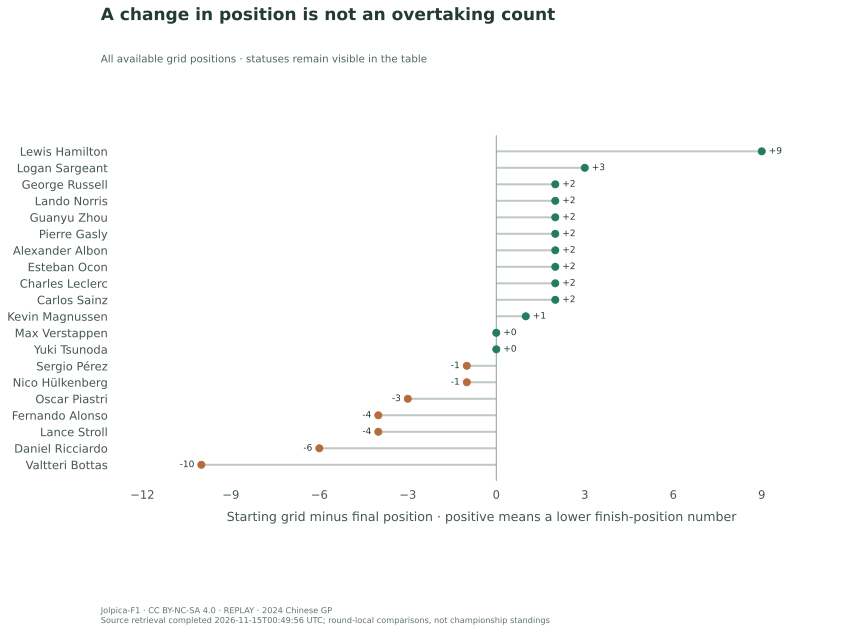

In [12]:
plot = ordering.loc[ordering.grid_to_finish.notna()].sort_values("grid_to_finish")
fig, ax = plt.subplots(figsize=(11.5, 9.4))
y = np.arange(len(plot))
ax.hlines(y, 0, plot.grid_to_finish, color="#BDC9C1", linewidth=2)
ax.scatter(
    plot.grid_to_finish,
    y,
    color=["#237B65" if v >= 0 else "#B66B3D" for v in plot.grid_to_finish],
    s=50,
    zorder=3,
)
for i, row in enumerate(plot.itertuples()):
    ax.annotate(
        f"{row.grid_to_finish:+.0f}",
        (row.grid_to_finish, i),
        xytext=(7 if row.grid_to_finish >= 0 else -7, 0),
        textcoords="offset points",
        ha="left" if row.grid_to_finish >= 0 else "right",
        va="center",
        fontsize=9,
    )
ax.axvline(0, color="#8E9F93", linewidth=1)
ax.set_yticks(y, plot.driver_name)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.margins(x=0.15)
ax.set_xlabel("Starting grid minus final position · positive means a lower finish-position number")
finish(
    fig,
    "A change in position is not an overtaking count",
    "All available grid positions · statuses remain visible in the table",
    chart_source,
    name="weekend-position-change",
)

### Decide whether the sprint belongs in this total

The two events award their own points. Add the published values only after retaining event identity; do not infer them from position, ignore fastest-lap points or treat missing points as zero. The experiment removes the sprint contribution while preserving both source columns. Team labels come from the constructor reference, and totals remain local to this one weekend.

In [13]:
%%sql points <<
SELECT constructor_id,constructor_name,count(*) AS drivers,
       sum(race_points)::DOUBLE AS grand_prix_points,
       sum(sprint_points)::DOUBLE AS sprint_points,
       sum(race_points+CASE WHEN {{ INCLUDE_SPRINT }} THEN sprint_points ELSE 0 END)::DOUBLE AS selected_points
FROM weekend GROUP BY constructor_id,constructor_name ORDER BY selected_points DESC,constructor_id;

In [14]:
display(points)
prose(
    f"Grand Prix points total **{points.grand_prix_points.sum():g}** and sprint points total **{points.sprint_points.sum():g}** across the returned entries. With sprint inclusion **{INCLUDE_SPRINT}**, this weekend's selected total is **{points.selected_points.sum():g}**. These are event points, not season standings or equal-condition performance."
)

,constructor_id,constructor_name,drivers,grand_prix_points,sprint_points,selected_points
0,red_bull,Red Bull,2,40.0,14.0,54.0
1,ferrari,Ferrari,2,22.0,9.0,31.0
2,mclaren,McLaren,2,22.0,5.0,27.0
3,mercedes,Mercedes,2,10.0,8.0,18.0
4,aston_martin,Aston Martin,2,7.0,0.0,7.0
5,haas,Haas F1 Team,2,1.0,0.0,1.0
6,alpine,Alpine F1 Team,2,0.0,0.0,0.0
7,rb,RB F1 Team,2,0.0,0.0,0.0
8,sauber,Sauber,2,0.0,0.0,0.0
9,williams,Williams,2,0.0,0.0,0.0


Grand Prix points total **102** and sprint points total **36** across the returned entries. With sprint inclusion **True**, this weekend's selected total is **138**. These are event points, not season standings or equal-condition performance.

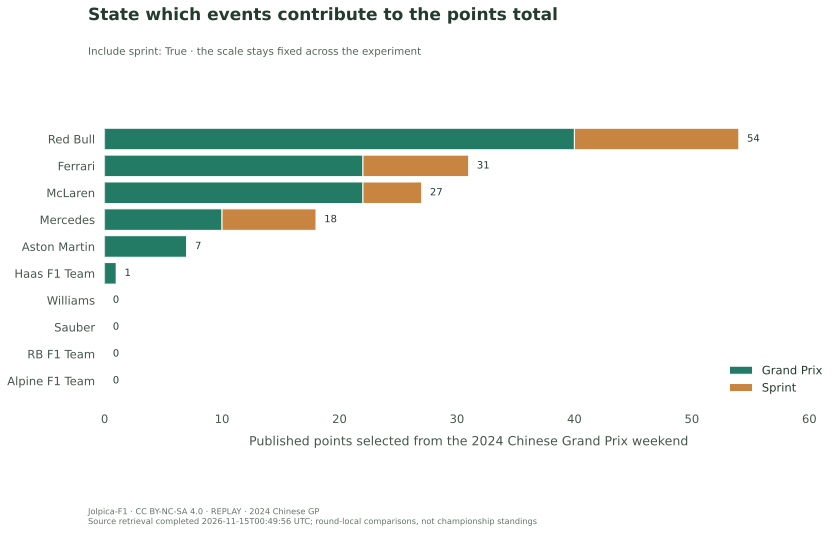

In [15]:
plot = points.sort_values("selected_points")
fig, ax = plt.subplots(figsize=(11.5, 7.9))
y = np.arange(len(plot))
ax.barh(y, plot.grand_prix_points, color="#237B65", label="Grand Prix")
if INCLUDE_SPRINT:
    ax.barh(y, plot.sprint_points, left=plot.grand_prix_points, color="#C78541", label="Sprint")
for i, row in enumerate(plot.itertuples()):
    ax.text(row.selected_points + 0.7, i, f"{row.selected_points:g}", va="center", fontsize=10)
ax.set_yticks(y, plot.constructor_name)
ax.set_xlim(0, max(60, float(plot.selected_points.max()) + 8))
ax.set_xlabel("Published points selected from the 2024 Chinese Grand Prix weekend")
ax.legend(loc="lower right")
finish(
    fig,
    "State which events contribute to the points total",
    f"Include sprint: {INCLUDE_SPRINT} · the scale stays fixed across the experiment",
    chart_source,
    name=f"weekend-points-{INCLUDE_SPRINT}",
)

In [16]:
%%sql checks <<
SELECT 'One event and circuit identity' AS check_name,(SELECT count(*)=1 AND bool_and(g.circuit_id IS NOT NULL) FROM calendar c LEFT JOIN circuits g USING(circuit_id) WHERE c.round=5) AS passed
UNION ALL SELECT 'Reference keys unique',(SELECT count(*)=count(DISTINCT driver_id) FROM drivers) AND (SELECT count(*)=count(DISTINCT constructor_id) FROM constructors)
UNION ALL SELECT 'Three classifications have unique driver IDs',(SELECT count(*)=count(DISTINCT driver_id) FROM race) AND (SELECT count(*)=count(DISTINCT driver_id) FROM qualifying) AND (SELECT count(*)=count(DISTINCT driver_id) FROM sprint)
UNION ALL SELECT 'Join preserves every race row',(SELECT count(*) FROM weekend)=(SELECT count(*) FROM race)
UNION ALL SELECT 'All joins resolved with source points',NOT EXISTS(SELECT 1 FROM weekend WHERE driver_name IS NULL OR constructor_name IS NULL OR qualifying_position IS NULL OR sprint_position IS NULL OR race_points IS NULL OR sprint_points IS NULL)
UNION ALL SELECT 'Nonnegative published points',NOT EXISTS(SELECT 1 FROM weekend WHERE race_points<0 OR sprint_points<0)
UNION ALL SELECT 'Fixed event identity',NOT EXISTS(SELECT 1 FROM race WHERE season<>2024 OR round<>5) AND NOT EXISTS(SELECT 1 FROM sprint WHERE season<>2024 OR round<>5)
UNION ALL SELECT 'Calendar orders distinct sessions',(SELECT sprint_utc<qualifying_utc AND qualifying_utc<race_start_utc FROM calendar WHERE round=5);

In [17]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert points.drivers.sum() == len(ordering)
assert np.isclose(
    points.selected_points.sum(),
    points.grand_prix_points.sum() + (points.sprint_points.sum() if INCLUDE_SPRINT else 0),
)
prose(
    "Eight SQL invariants and team/points reconciliation passed. Query populations, joins and event identity remain explicit."
)

,check_name,passed
0,One event and circuit identity,True
1,Reference keys unique,True
2,Three classifications have unique driver IDs,True
3,Join preserves every race row,True
4,All joins resolved with source points,True
5,Nonnegative published points,True
6,Fixed event identity,True
7,Calendar orders distinct sessions,True


Eight SQL invariants and team/points reconciliation passed. Query populations, joins and event identity remain explicit.

### Experiment: omit the sprint contribution

Change only **INCLUDE_SPRINT=True → False**. The seven source tables, event context, position chart and both source-point columns must remain unchanged. Predict the selected total's change from the sprint column before rerunning. A different total answers a different aggregation question; it does not revise the underlying race or championship.

Attribution: [Jolpica-F1](https://github.com/jolpica/jolpica-f1), data and derived data outputs under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). No affiliation with Formula 1 or the FIA.

In [18]:
session.close()
recording.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-f1](https://github.com/Query-farm/vgi-f1)